# M9 — Final results on the test questions

Until now every number came from the 40 **practice** questions, which we used to build and fix things.
M9 runs everything **once more on the 80 test questions we never looked at**. That's the fair exam.

**What's new in this step**
| Idea | Plain meaning |
|---|---|
| **3 runs** | the AI doesn't answer exactly the same way every time, so each version runs 3 times and we average |
| **95% confidence interval (CI)** | "the true accuracy is probably between X and Y". Made by *bootstrap*: re-draw the 80 questions with replacement 10,000 times |
| **McNemar test** | are two versions *really* different, or is it luck? It only looks at questions where they disagree. p < 0.05 = probably real |
| **AI grader** | a bigger model (`gpt-5`) grades answers without knowing the version or the gold answer |
| **Cohen's kappa** | how much two graders agree, beyond luck (1 = always, 0 = chance). You grade 30 answers; we compare with the AI grader |
| **Failure analysis** | every wrong answer sorted into a failure type |

**Files in this step**
| File | What it does |
|---|---|
| `harness/stats.py` | accuracy, CIs, McNemar, conversations, extras → `results/final_summary.json` |
| `harness/chart.py` | the accuracy chart → `docs/accuracy_ci.png` |
| `harness/judge.py` | AI grader; `--sheet` makes your 30-answer grading sheet; `--kappa` compares |
| `harness/failures.py` | sorts wrong answers → `results/failures.md` |

**How the runs were made:** 5 chains ran at the same time. Each had its own copy of the Qdrant search index
(`QDRANT_PATH=data/qdrant_2` ...), because local Qdrant allows one program at a time.

In [1]:
import sys, json
sys.path += ["../harness", "../agent", "../catalog"]
import stats
stats.main()

version    runs  accuracy  95% CI          easy  medium tricky  F1    shown  med s  med $
A             3  0.904     [0.842, 0.958]  1.00  0.88   0.83   0.96  1.00     3.2  0.0012
B             3  0.758     [0.667, 0.846]  1.00  0.48   0.80   0.67  0.62     3.3  0.0006
C             3  0.683     [0.592, 0.771]  0.91  0.38   0.76   0.67  0.57     9.4  0.0011
D             3  0.767     [0.675, 0.854]  0.97  0.52   0.81   0.79  0.79     3.3  0.0006


E             3  0.800     [0.725, 0.871]  0.94  0.54   0.92   0.81  0.82     8.2  0.0019
E_memory      3  0.925     [0.879, 0.963]  0.96  0.83   0.99   0.85  0.81     8.6  0.0019

McNemar (right in >= 2 of 3 runs)       only first right  only second right  p
  A         vs B                               11                 1         0.0063
  B         vs C                                6                 2         0.2891
  C         vs D                                4                 7         0.5488
  D         vs E                                7                 9         0.8036
  B         vs D                                4                 3         1.0000
  A         vs D                               11                 0         0.0010
  A         vs E                               14                 5         0.0636
  E         vs E_memory                         0                15         0.0001

Conversations (15 x 3 turns)   all    turn1  turn2  turn3   95% CI
  E     

  C_no_rerank    0.762  [0.675, 0.850]  shown 0.71

Bigger catalog (1 run each; 28 = mean of the 3 main runs)   accuracy / avg $ per question
  A  28: 0.904 / $0.0013   100: 0.900 / $0.0037   250: 0.900 / $0.0077
  B  28: 0.758 / $0.0007   100: 0.775 / $0.0007   250: 0.725 / $0.0008


  C  28: 0.683 / $0.0013   100: 0.700 / $0.0012   250: 0.725 / $0.0012
  D  28: 0.767 / $0.0008   100: 0.775 / $0.0008   250: 0.738 / $0.0008

Saved to /Users/anshikapuneet/Documents/Claude_history/capstone_project/results/final_summary.json


## 1. The chart
Dot = average over 3 runs × 80 questions. Line = 95% confidence interval. If two lines overlap a lot, the
difference may be luck. The McNemar test above says for sure.

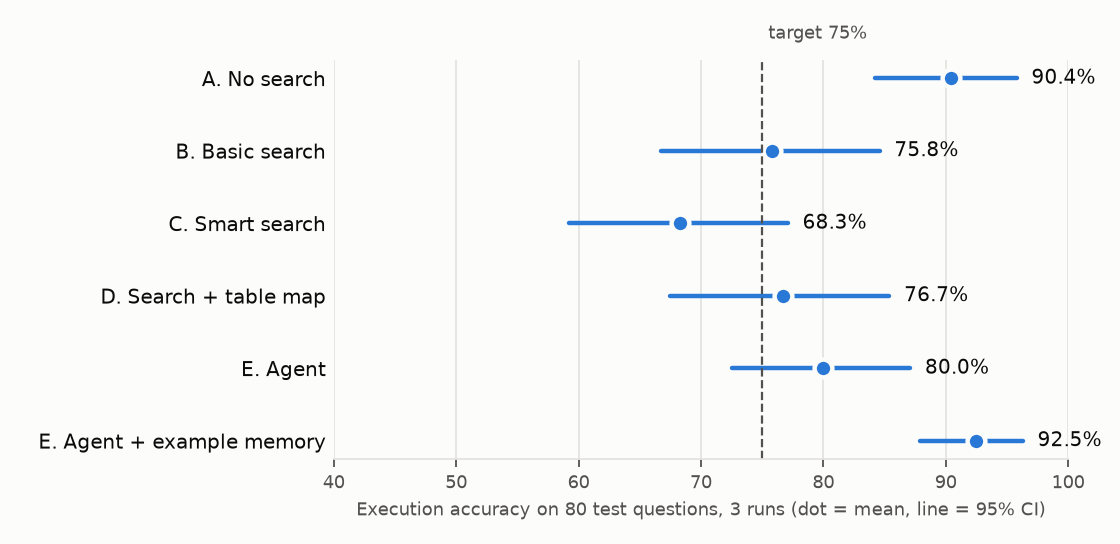

In [2]:
from IPython.display import Image
Image("../docs/accuracy_ci.png")

## 2. Did we hit the targets we set before building? (from the design doc)

In [3]:
s = json.load(open("../results/final_summary.json"))
q, conv = s["questions"], s["conversations"]
best = max(q, key=lambda v: q[v]["accuracy"])
lift = q[best]["accuracy_hard"] - q["B"]["accuracy_hard"]
d_drop = q["D"]["accuracy"] - s["catalog"]["D"]["250"]["accuracy"]
rows = [
    ("Execution accuracy (best version)", f"{best}: {q[best]['accuracy']:.1%}", ">= 75%", q[best]["accuracy"] >= 0.75),
    ("Lift on medium+tricky over B", f"{lift * 100:+.1f} points", ">= +10", lift >= 0.10),
    ("Table F1 (best version)", f"{q[best]['table_f1']:.2f}", ">= 0.85", q[best]["table_f1"] >= 0.85),
    ("Follow-ups with chat memory", f"{conv['E']['accuracy']:.1%}", ">= 80%", conv["E"]["accuracy"] >= 0.80),
    ("Median time / cost (best)", f"{q[best]['median_seconds']} s / ${q[best]['median_cost_usd']}", "<= 10 s, <= $0.02",
     q[best]["median_seconds"] <= 10 and q[best]["median_cost_usd"] <= 0.02),
    ("D drop at 250 tables", f"{d_drop * 100:.1f} points", "<= 10", d_drop <= 0.10),
]
for name, value, target, ok in rows:
    print(f"{'MET ' if ok else 'MISS'}  {name:36s} {value:22s} target {target}")

MET   Execution accuracy (best version)    E_memory: 92.5%        target >= 75%
MET   Lift on medium+tricky over B         +27.1 points           target >= +10
MET   Table F1 (best version)              0.85                   target >= 0.85
MET   Follow-ups with chat memory          89.6%                  target >= 80%
MET   Median time / cost (best)            8.6 s / $0.0019        target <= 10 s, <= $0.02
MET   D drop at 250 tables                 2.9 points             target <= 10


## 3. AI grader
It sees: question, warehouse rules, SQL, result, written answer (E only). It does **not** see the version or the
gold answer. The last column shows how well "acceptable" agrees with our execution-accuracy score.

In [4]:
import judge
judge.summarize()


version    acceptable  relevance  caveats  faithful  agree-with-exec-accuracy (kappa)
A          0.963       4.86       4.99         -     0.52
B          0.762       4.17       4.80         -     0.79
C          0.738       4.14       4.86         -     0.87
D          0.787       4.29       4.75         -     0.70
E          0.925       4.81       4.94      4.95     0.46
E_memory   0.925       4.89       4.96      4.83     0.92


**Your part (about 20 minutes):** `results/human_grading.csv` has 30 answers with the version hidden. Fill the
column `your_acceptable (yes/no)` (use `warehouse/rules.md`), save it, then run
`.venv/bin/python harness/judge.py --kappa`. The design-doc target is kappa ≥ 0.6.

## 4. Failure analysis (first test run of each version)

In [5]:
print(open("../results/failures.md").read())

| Failure type | A | B | C | D | E | E_memory | All |
|---|---|---|---|---|---|---|---|
| wrong_calculation | 5 | 6 | 4 | 7 | 2 | 2 | 26 |
| missing_connecting_table | 0 | 5 | 10 | 3 | 0 | 0 | 18 |
| strict_grading | 3 | 3 | 2 | 3 | 6 | 0 | 17 |
| wrong_lookalike | 0 | 4 | 5 | 2 | 2 | 0 | 13 |
| not_sure | 0 | 0 | 1 | 2 | 6 | 4 | 13 |
| wrong_time_window | 0 | 1 | 0 | 0 | 1 | 0 | 2 |
| wrong_join | 0 | 0 | 0 | 0 | 0 | 1 | 1 |
| made_up_column | 0 | 0 | 1 | 0 | 0 | 0 | 1 |
| **wrong answers** | 8 | 19 | 23 | 17 | 17 | 7 | 91 |

**Examples (first per version and type):**

- **A / wrong_calculation** (q046, medium): For campaign 94399 yesterday, what CTR did heavy shoppers have? → Used shopping_depth = 5 instead of the correct 3 for heavy shoppers, applying the wrong filter.
- **A / strict_grading** (q052, medium): Brand 268781: clicks from users with the highest spending level, 6-12 May? → Returned a daily breakdown instead of a single total, so the format didn’t match the expected answe

## 5. What it all means
See the **Results** and **Failure analysis** sections in the README. They're written from the numbers above.